## **Import Necessary Libraries/Packages**

In [1]:
!pip install ultralytics roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.9/207.9 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 89.2 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.92
    Uninstalling opencv-python-headless-4.13.0.92:
      Successfully uninstalled opencv-python-headless-4.13.0.92
  Attempting uninstall: idna
    Found existing installation: idna 3.15
    Uninstalling idna-3.15:
      Successfully uninstalled idna-3.15


In [27]:
import os
import yaml
import random
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
from PIL import Image, ImageDraw
from google.colab import userdata
from pathlib import Path
from roboflow import Roboflow
from ultralytics import YOLO
from google.colab import files
from IPython.display import display
from google.colab.patches import cv2_imshow

## **Data Loading & Preparation**

In [3]:
# Roboflow API configuration
api_key = userdata.get('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=api_key)

In [4]:
# Dataset download
project = rf.workspace("brad-dwyer").project("pklot-1tros")
dataset = project.version(4).download("yolov8", location="/content/pklot")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/pklot in yolov8:: 100%|██████████| 24842/24842 [00:03<00:00, 7987.93it/s]


In [5]:
# Dataset folder configuration
PKLOT_DIR = Path("/content/pklot")
CLASS_NAMES = ["space-empty", "space-occupied"]

if (PKLOT_DIR / "images").exists():
    image_paths = {"train": PKLOT_DIR / "images/train", "val": PKLOT_DIR / "images/val", "test": PKLOT_DIR / "images/test"}
    label_paths = {"train": PKLOT_DIR / "labels/train", "val": PKLOT_DIR / "labels/val", "test": PKLOT_DIR / "labels/test"}
else:
    image_paths = {"train": PKLOT_DIR / "train/images", "val": PKLOT_DIR / "valid/images", "test": PKLOT_DIR / "test/images"}
    label_paths = {"train": PKLOT_DIR / "train/labels", "val": PKLOT_DIR / "valid/labels", "test": PKLOT_DIR / "test/labels"}

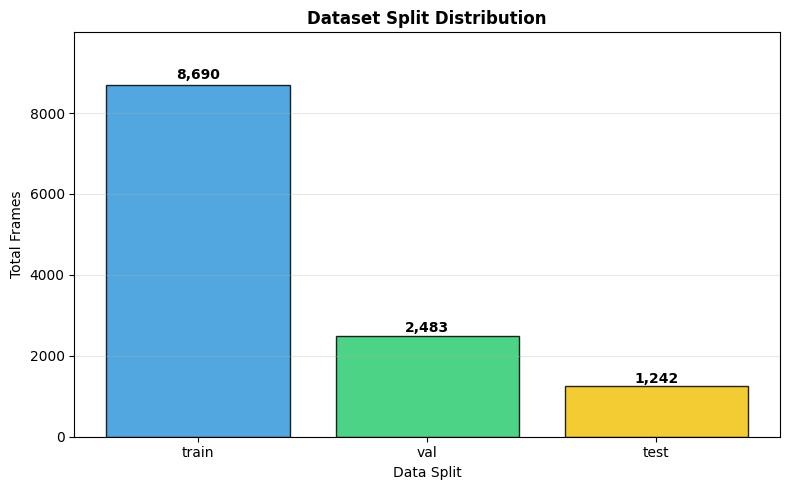

In [6]:
# Dataset split distribution
split_counts = {}
for split, path in image_paths.items():
    if path.exists():
        n_img = len(list(path.glob("*.jpg")) + list(path.glob("*.png")) + list(path.glob("*.jpeg")))
        split_counts[split] = n_img
    else:
        split_counts[split] = 0

plt.figure(figsize=(8, 5))
bars = plt.bar(
    split_counts.keys(),
    split_counts.values(),
    color=['#3498db', '#2ecc71', '#f1c40f'],
    alpha=0.85,
    edgecolor='black',
)

max_val = max(split_counts.values()) if split_counts else 0
for bar in bars:
    height = bar.get_height()
    y_pos = height + (max_val * 0.015 if max_val > 0 else 0.2)
    plt.text(
        bar.get_x() + bar.get_width()/2.,
        height + max(1, height * 0.01),
        f'{height:,}', ha='center',
        va='bottom',
        fontweight='bold',
    )

if max_val == 0:
    plt.ylim(0, 10)
else:
    plt.ylim(0, max_val * 1.15)

plt.title("Dataset Split Distribution", fontsize=12, fontweight='bold')
plt.ylabel("Total Frames")
plt.xlabel("Data Split")
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Read label train: 8690it [00:00, 15215.60it/s]
Read label val: 2483it [00:00, 14964.29it/s]
Read label test: 1242it [00:00, 14952.65it/s]


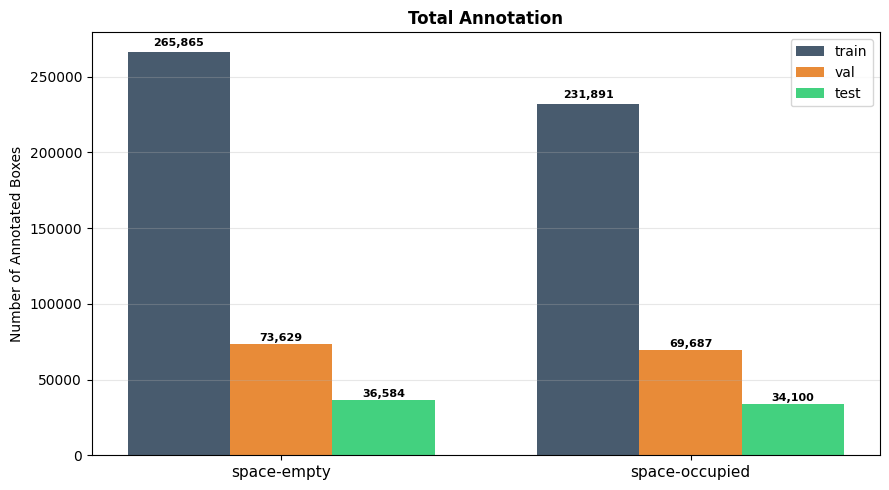

In [7]:
# Count annotations of each class
def count_annotations(paths):
    counts = {split: {c: 0 for c in CLASS_NAMES} for split in paths.keys()}
    for split, lbl_dir in paths.items():
        if not lbl_dir.exists():
            continue

        for lbl_path in tqdm(lbl_dir.glob("*.txt"), desc=f"Read label {split}"):
            for line in lbl_path.read_text().splitlines():
                parts = line.strip().split()
                if parts:
                    cls_id = int(parts[0])
                    if cls_id < len(CLASS_NAMES):
                        counts[split][CLASS_NAMES[cls_id]] += 1
    return counts

ann_counts = count_annotations(label_paths)
splits_list = list(ann_counts.keys())
x = np.arange(len(CLASS_NAMES))
width = 0.25
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#34495e", "#e67e22", "#2ecc71"]

for i, (split, color) in enumerate(zip(splits_list, colors)):
    vals = [ann_counts[split][c] for c in CLASS_NAMES]
    bars = ax.bar(x + i*width, vals, width, label=split, color=color, alpha=0.9)
    for bar, v in zip(bars, vals):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + max(1, v*0.01),
            f"{v:,}",
            ha="center",
            va="bottom",
            fontsize=8,
            fontweight='bold',
        )

ax.set_xticks(x + width)
ax.set_xticklabels(CLASS_NAMES, fontsize=11)
ax.set_ylabel("Number of Annotated Boxes")
ax.set_title("Total Annotation", fontsize=12, fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Dataset Image Visualization
def draw_yolo_boxes(img: Image.Image, lbl_path: Path):
    draw = ImageDraw.Draw(img)
    fw, fh = img.size
    colors_cls = {0: "#00cc66", 1: "#ff4444"}

    for line in lbl_path.read_text().splitlines():
        parts = line.strip().split()
        if len(parts) < 5:
            continue

        cls_id = int(parts[0])
        cx, cy, bw, bh = map(float, parts[1:5])

        x1 = (cx - bw/2) * fw; y1 = (cy - bh/2) * fh
        x2 = (cx + bw/2) * fw; y2 = (cy + bh/2) * fh

        color = colors_cls.get(cls_id, "#ffffff")
        draw.rectangle([x1, y1, x2, y2], outline=color, width=2)
        draw.text((x1+2, y1+2), CLASS_NAMES[cls_id], fill=color)
    return img


def show_sample_images(img_dir: Path, lbl_dir: Path, n: int = 6):
    img_paths = list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png")) + list(img_dir.glob("*.jpeg"))
    if not img_paths:
        print(f"Invalid or empty image directory: {img_dir}")
        return

    random.shuffle(img_paths)
    img_paths = img_paths[:n]

    cols = min(n, 3)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*5, rows*4))
    axes = np.array(axes).flatten()

    for i, img_path in enumerate(img_paths):
        lbl_path = lbl_dir / (img_path.stem + ".txt")
        img = Image.open(img_path).convert("RGB")
        if lbl_path.exists():
            img = draw_yolo_boxes(img, lbl_path)

        axes[i].imshow(img)
        axes[i].axis("off")
        axes[i].set_title(img_path.name, fontsize=8)

    for ax in axes[len(img_paths):]:
        ax.axis("off")

    fig.suptitle("Image Visualization", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

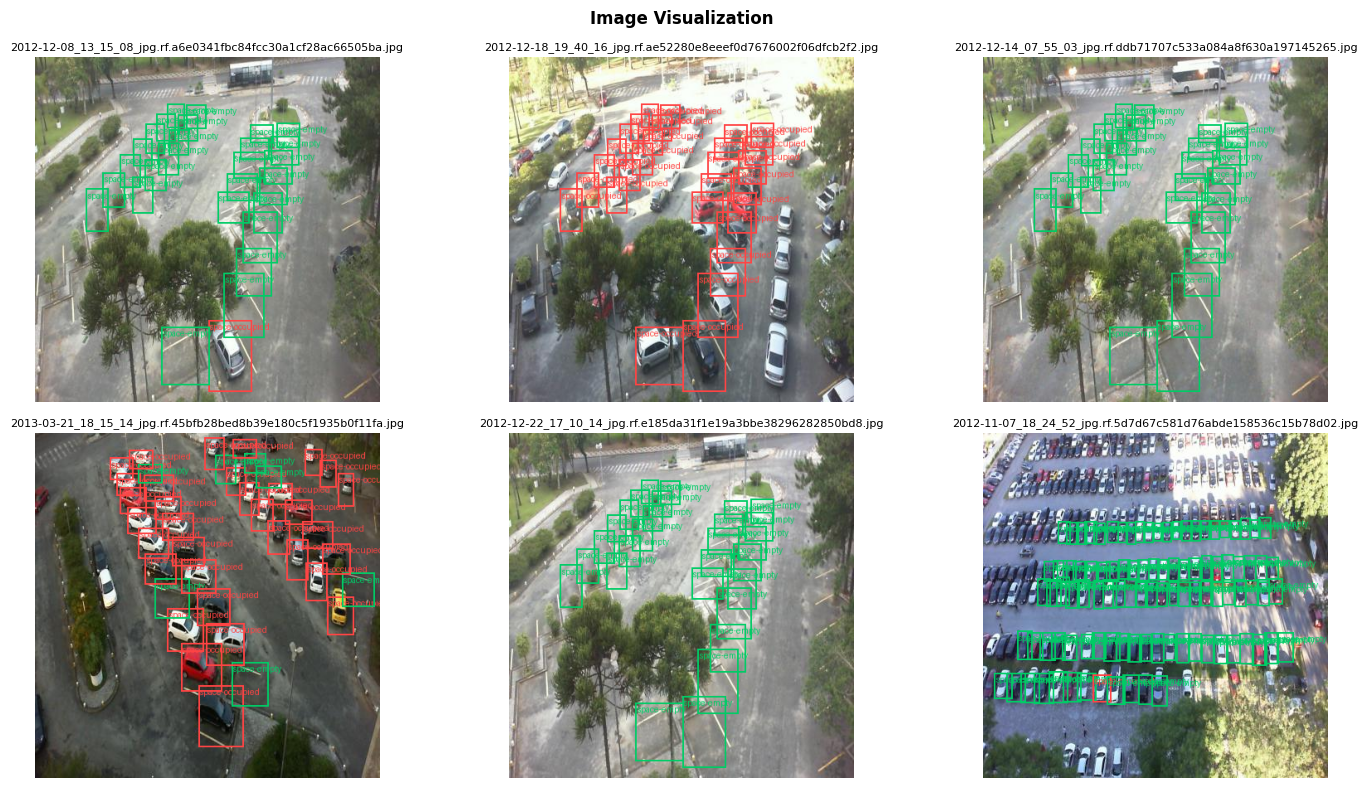

In [9]:
show_sample_images(image_paths["train"], label_paths["train"], n=6)

## **YAML Configuration**

In [10]:
YAML_PATH = Path("/content/pklot/data.yaml")
with open(YAML_PATH) as f:
    dataset_cfg = yaml.safe_load(f)

dataset_cfg["path"] = "/content/pklot"
dataset_cfg["train"] = "train/images"
dataset_cfg["val"] = "valid/images"
dataset_cfg["test"] = "test/images"

if "roboflow" in dataset_cfg:
    del dataset_cfg["roboflow"]

with open(YAML_PATH, "w") as f:
    yaml.dump(dataset_cfg, f, default_flow_style=False, sort_keys=False)

print(open(YAML_PATH).read())

names:
- space-empty
- space-occupied
nc: 2
test: test/images
train: train/images
val: valid/images
path: /content/pklot



## **Model Training**

In [11]:
model = YOLO('yolov8n.pt')
results = model.train(data='/content/pklot/data.yaml', epochs=50, batch=16, imgsz=640, device=0, plots=True, patience=10)

Ultralytics 8.4.56 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pklot/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10, perspect

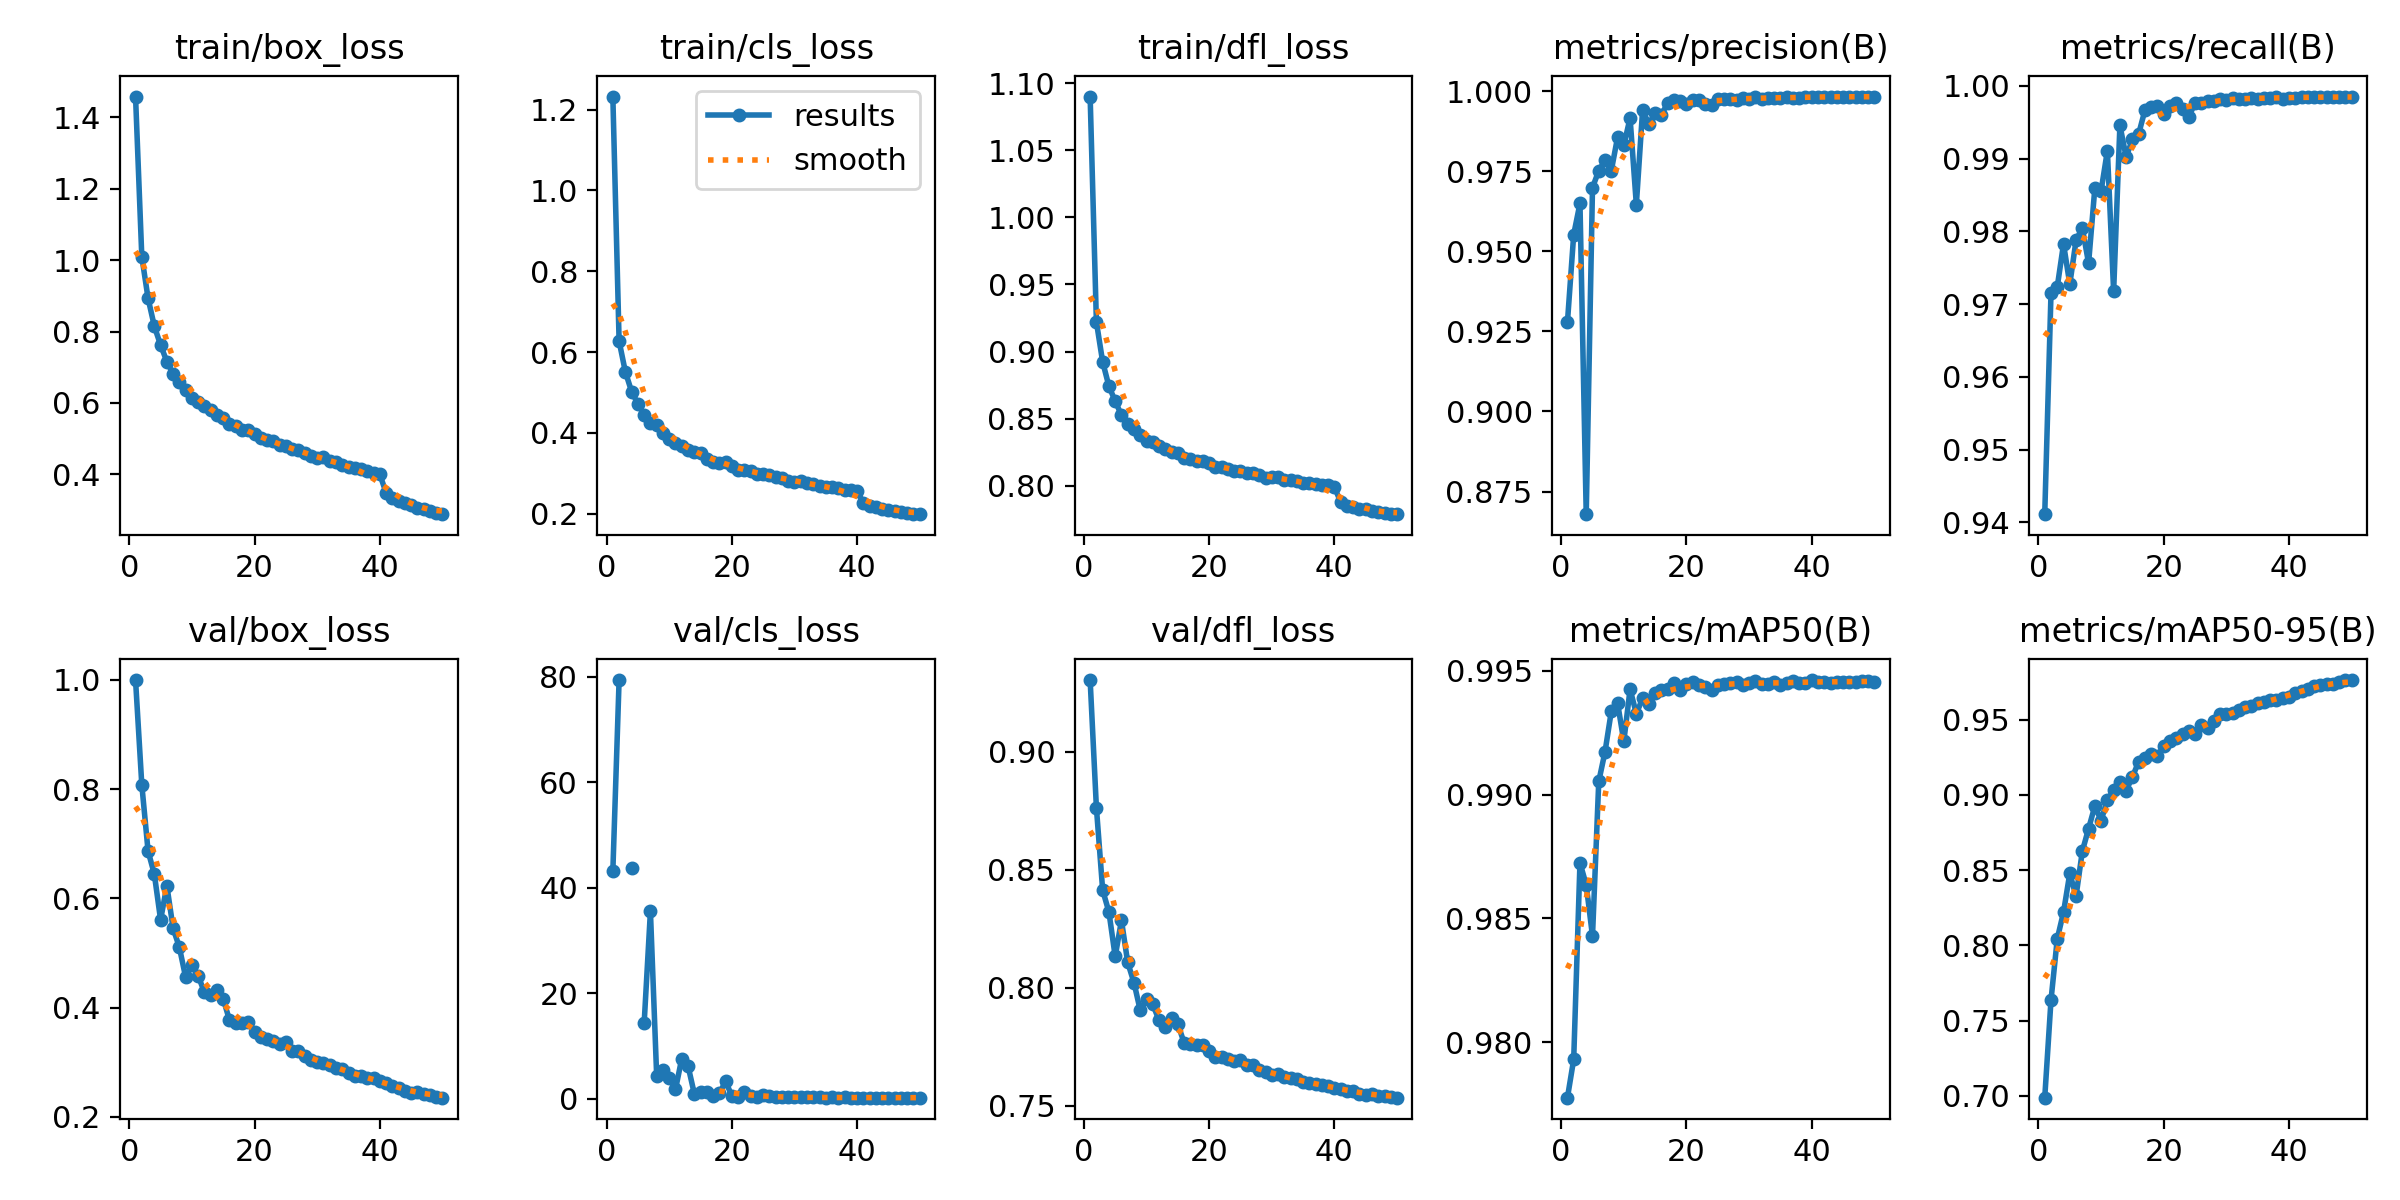

In [23]:
# Training Visualization
display(Image('/content/runs/detect/train/results.png', width=1000))

In [25]:
# Export Model best.pt to ONNX format
best_model = YOLO('/content/runs/detect/train/weights/best.pt')
onnx_path = best_model.export(format="onnx")

Ultralytics 8.4.56 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from '/content/runs/detect/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (6.0 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxslim>=0.1.71', 'onnxruntime'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 322ms
Prepared 4 packages in 1.59s
Installed 4 packages in 291ms
 + colorama==0.4.6
 + onnx==1.21.0
 + onnxruntime==1.26.0
 + onnxslim==0.1.94

requirements: AutoUpdate success ✅ 2.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.21.0 opset 20...
ONNX: slimming with 

## **Folder Download**

In [26]:
files.download('/content/runs.zip')
files.download('/content/pklot.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Evaluation**

In [14]:
model_best = YOLO('/content/runs/detect/train/weights/best.pt')
test_metrics = model_best.val(split='test')

Ultralytics 8.4.56 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 931.8±310.6 MB/s, size: 36.1 KB)
val: Scanning /content/pklot/test/labels... 1242 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1242/1242 1.0Kit/s 1.2s
val: New cache created: /content/pklot/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 78/78 2.8it/s 28.3s
                   all       1242      70684      0.997      0.997      0.994       0.98
           space-empty       1041      36584      0.996      0.996      0.994      0.984
        space-occupied        991      34100      0.999      0.998      0.994      0.976
Speed: 1.5ms preprocess, 4.4ms inference, 0.0ms loss, 4.5ms postprocess per image
Results saved to /content/runs/detect/val


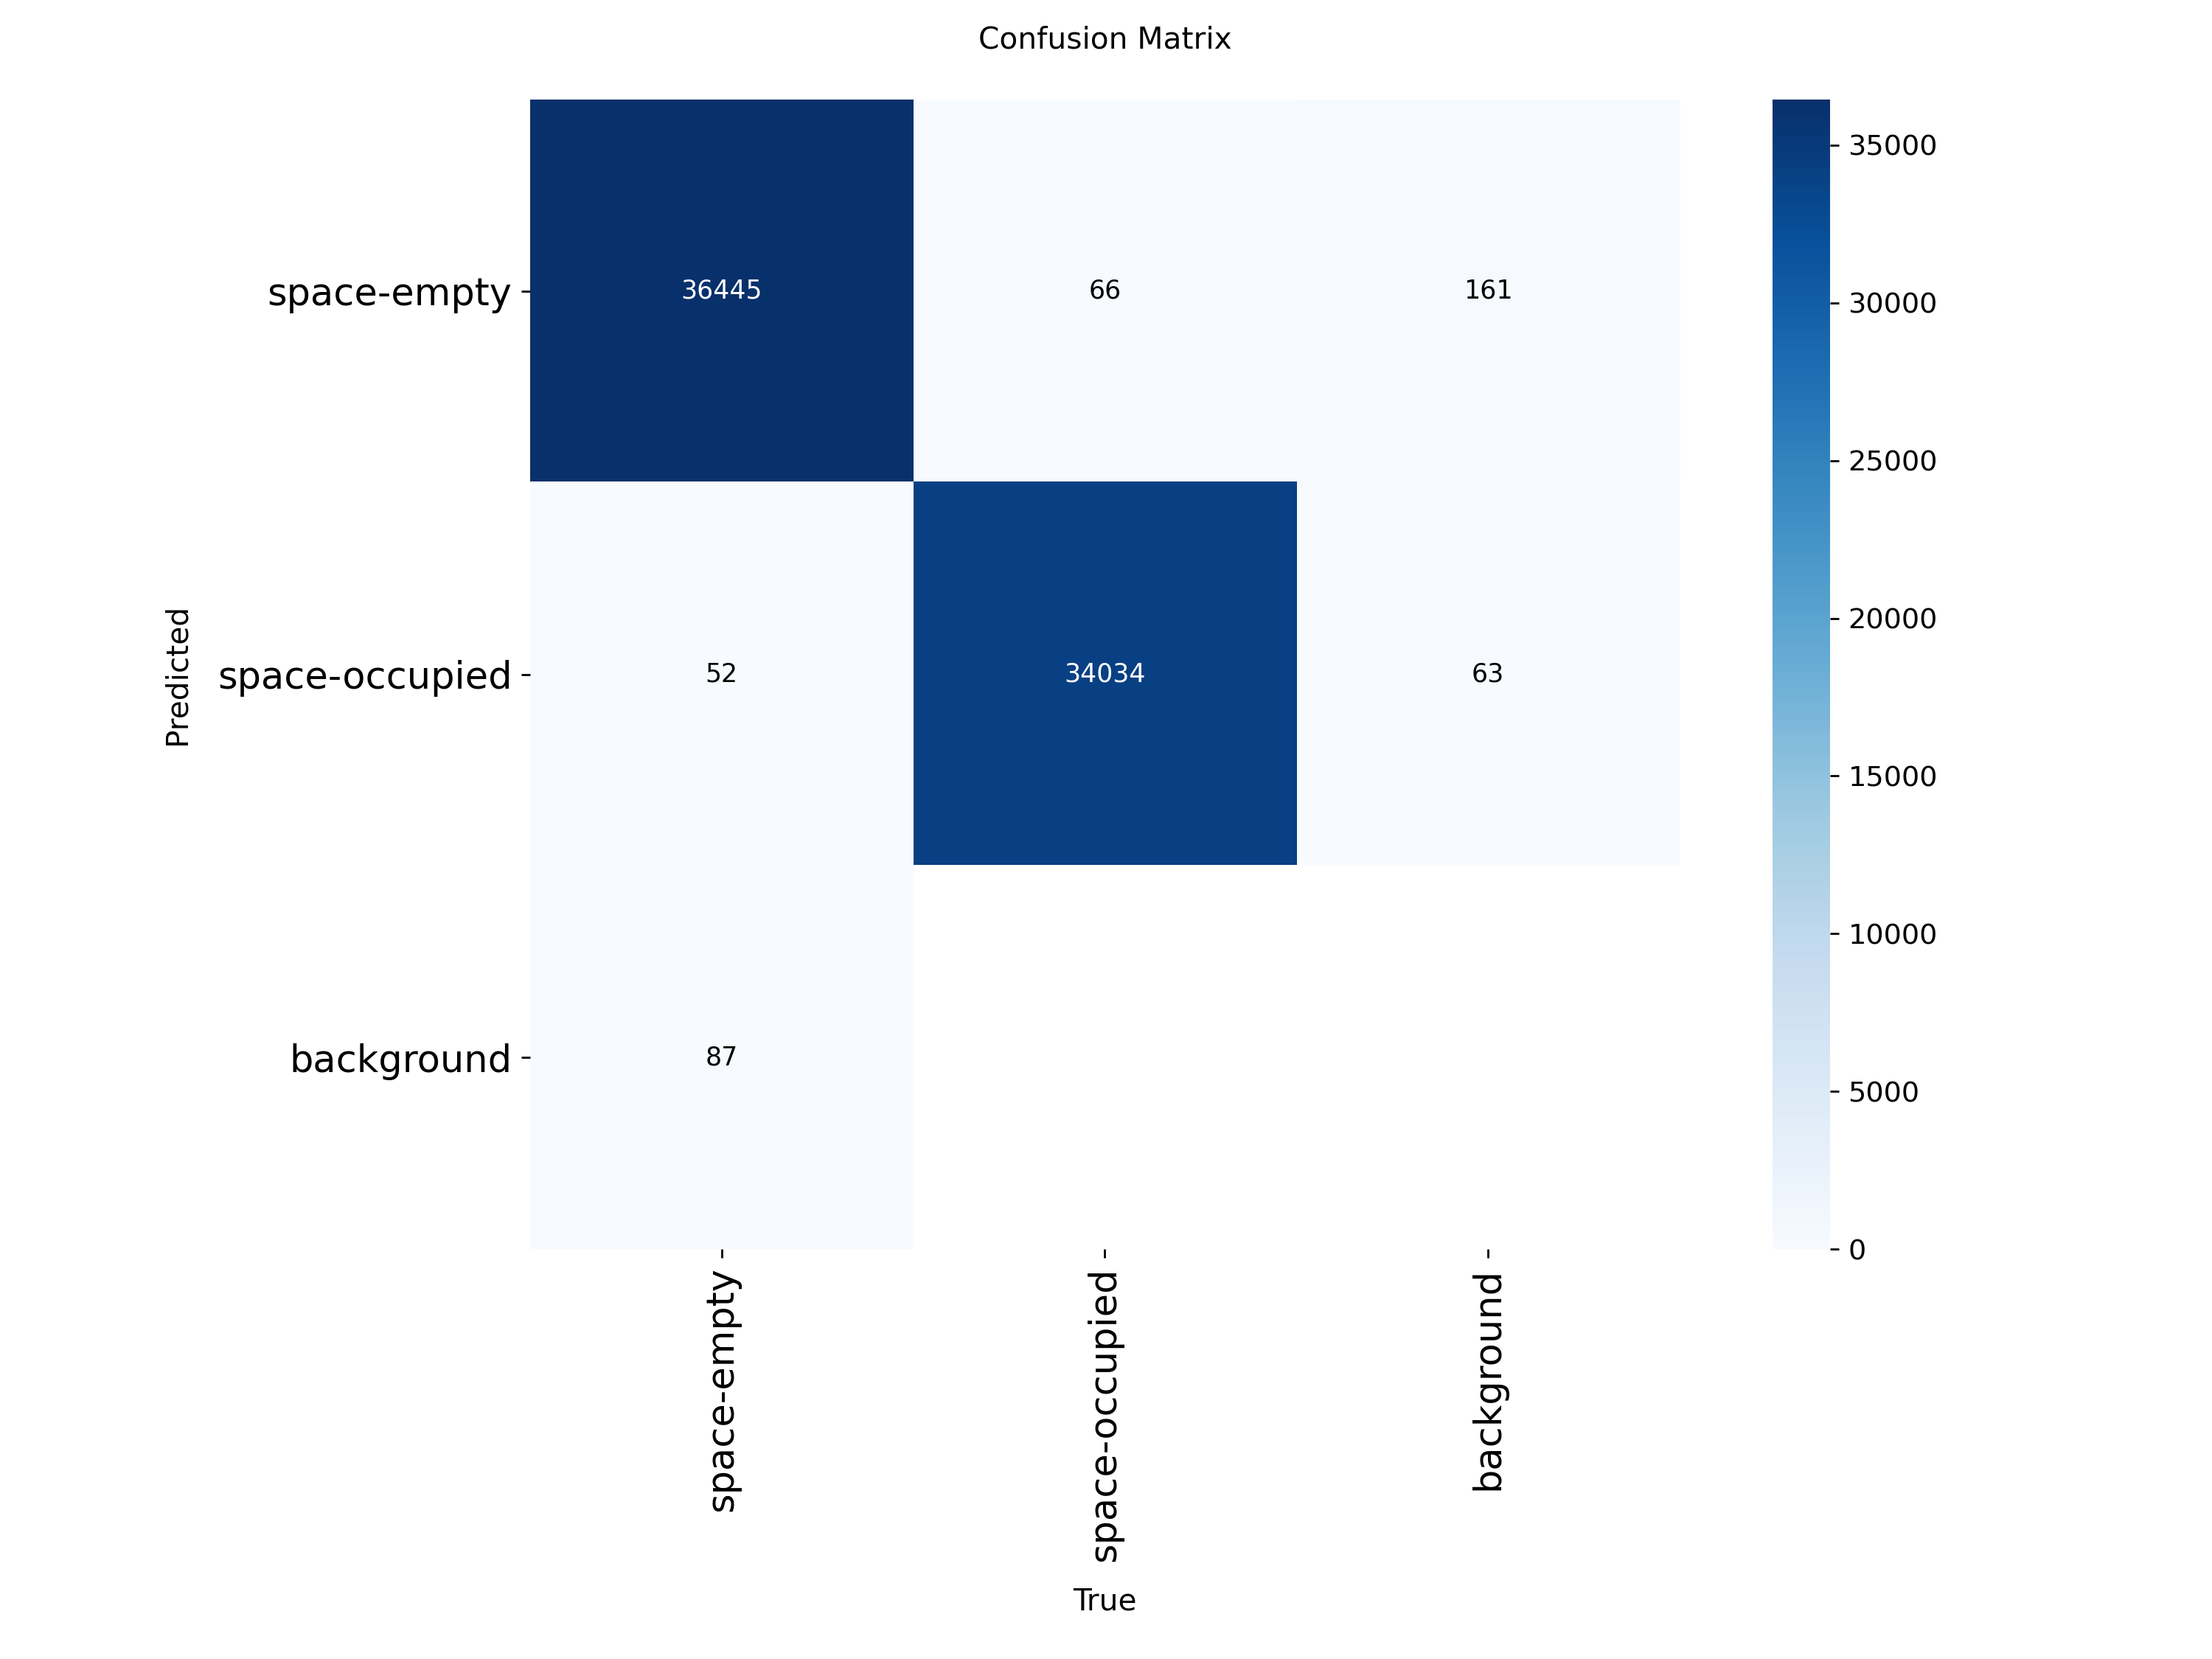

In [24]:
# Confusion Matrix
display(Image('/content/runs/detect/val/confusion_matrix.png', width=1000))

## **Inference**


image 1/1 /content/pklot/test/images/2012-12-19_15_15_11_jpg.rf.cfaa958dc4ac2e1d1bad4ca89ffc8529.jpg: 640x640 28 space-occupieds, 9.6ms
Speed: 3.8ms preprocess, 9.6ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


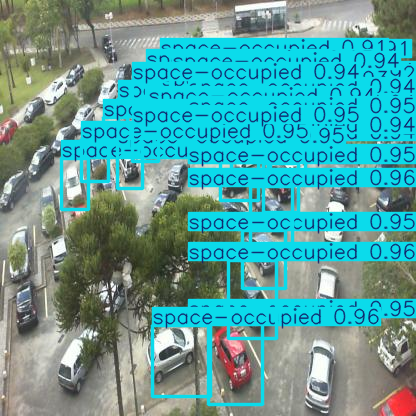

In [33]:
results = model_best.predict(source='/content/pklot/test/images/2012-12-19_15_15_11_jpg.rf.cfaa958dc4ac2e1d1bad4ca89ffc8529.jpg', save=False)
rendered_img = results[0].plot()
cv2_imshow(rendered_img)